# Delivery Lead-Time Regression

**IT5006 · Phase 3**

At order placement, estimate the fractional days until customer receipt. This notebook follows the project’s analytical sequence from raw tables and information availability through chronological validation, model comparison, interpretation and deployment. It reads frozen results; the complete training command is documented below.

## Summary

The chronological procedure retained **HGB_risk**. Test MAE was **3.4343 days** on **18,603** June–August purchases. Error varies by month, route and delivery duration. Completed-delivery coverage, selection-label maturity and prior historical test exposure limit the interpretation; these results do not establish prospective operational accuracy.

## Problem Scoping Checklist

| Check | Assessment |
|---|---|
| Derivable target | Receipt minus purchase in fractional days from the fixed course tables. |
| Realistic inputs | Purchase-time order/quote/product/location inputs; archived availability remains an assumption. |
| Sufficient signal | Earlier EDA motivates predictors; the time evaluation tests their transfer to later orders. |
| Skew and tail | Keep valid slow orders, use MAE and report tail magnitude and contribution. |
| Stakeholder | Fulfilment and customer-service teams can use provisional estimates with human escalation. |

## Context & Methods

The primary comparison uses the same feature schema and preprocessing for OLS, Ridge, one tree, RF and HGB. The target remains original days. Five expanding windows validate January–May 2018; the test contains June–August purchases. Training requires both an embargo and receipt before the fitting cutoff. Selection outcomes must be observed before 1 June. All choices freeze before test assessment.

### Key assumptions

The source snapshot records completed outcomes and static metadata, not a full historical availability log. Observed completed deliveries form a conditional population. May has incomplete label maturity at selection time. The historical orders have been used in prior development. No live prospective evidence is claimed.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display
root = next(q for p in [Path.cwd(), *Path.cwd().parents] for q in [p, p / "Phase_3"] if (q / "src/regression").is_dir())
sys.path.insert(0, str(root / "src"))
from regression import config as C
from regression.reporting import table, draw
from regression.pipeline import read
import matplotlib.pyplot as plt
pd.options.display.float_format = "{:,.4f}".format
print("Phase 3 regression — saved, frozen evidence")

Phase 3 regression — saved, frozen evidence


## 1. Data Sources and Order-Level Preparation

Seven course tables are linked using documented identifiers, with line items aggregated before order modelling. The pre-model audit independently reconstructed targets, checked basket totals and verified that perturbing outcome fields leaves purchase features unchanged. The earlier V2 numeric fields were matched on every valid order.

In [2]:
display(table("source_inventory")[["table", "file", "rows"]])
display(table("cohort_flow"))
audit = read("audit_pass.json")
checks = ["zero_future_training_labels", "zero_unavailable_selection_labels", "train_score_disjoint", "test_excluded_from_development"]
display(pd.DataFrame({"Check": checks, "Passed": [audit[k] for k in checks]}))

,table,file,rows
0,orders,olist_orders_dataset.csv,99441
1,items,olist_order_items_dataset.csv,112650
2,customers,olist_customers_dataset.csv,99441
3,sellers,olist_sellers_dataset.csv,3095
4,products,olist_products_dataset.csv,32951
5,geo,olist_geolocation_dataset.csv,1000163
6,translation,product_category_name_translation.csv,71


,step,orders
0,Source orders,99441
1,Orders with items,98666
2,Valid delivered orders (all dates),96470
3,Excluded outside Jan 2017-Aug 2018,267
4,Phase 3 modelling cohort,96203


,Check,Passed
0,zero_future_training_labels,True
1,zero_unavailable_selection_labels,True
2,train_score_disjoint,True
3,test_excluded_from_development,True


## 2. Chronological Windows and Label Availability

The 39-day embargo is calibrated from outcomes already observed before the first deployment date. A strict receipt cutoff remains necessary: some longer labels cross even that gap. Validation membership is based on purchase month, not on completing within that month. Outcomes unavailable before final fitting are excluded from selection scores, with their coverage explicitly reported.

,fold,cutoff,train_n,score_n,score_label_coverage,labels_at_or_after_cutoff
0,fold1,2018-01-01,34246,7068,0.9999,0
1,fold2,2018-02-01,42450,6551,0.9994,0
2,fold3,2018-03-01,47940,6996,0.9990,0
3,fold4,2018-04-01,54882,6715,0.9878,0
4,fold5,2018-05-01,62130,4406,0.6528,0
5,final,2018-06-01,68916,18603,1.0000,0


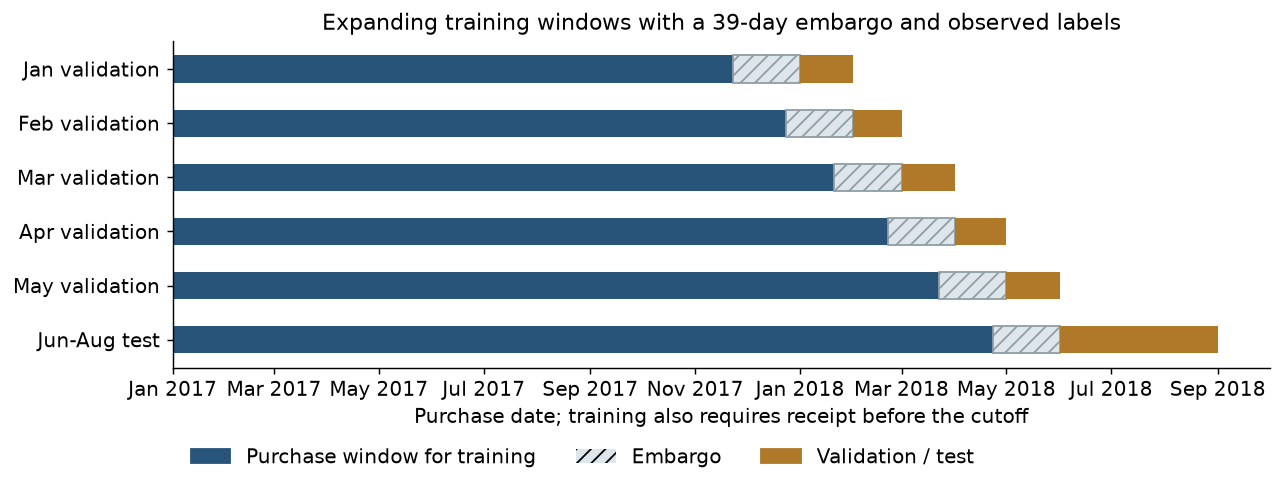

In [3]:
display(table("fold_table")[["fold", "cutoff", "train_n", "score_n", "score_label_coverage", "labels_at_or_after_cutoff"]])
draw("01_windows"); plt.show()

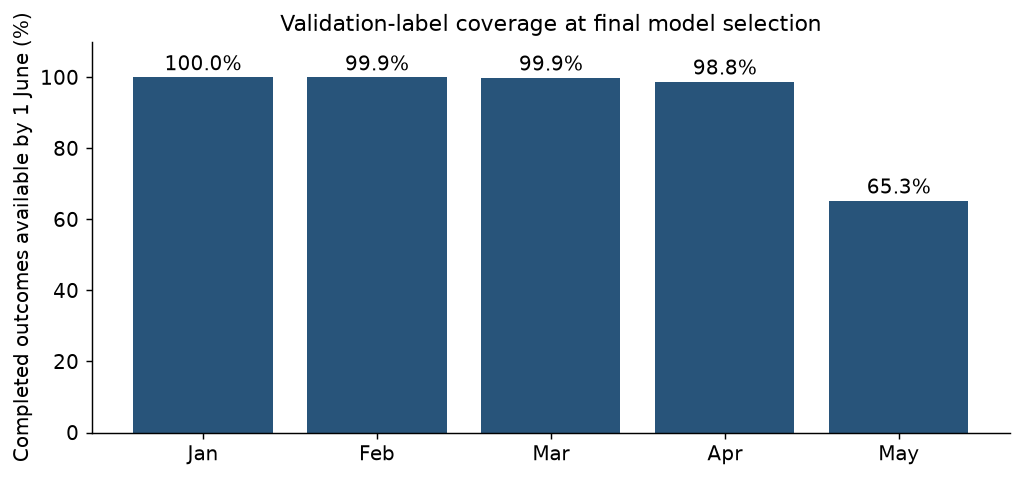

,candidate,family,five_month_mae,jan_apr_mae,five_month_rank,jan_apr_rank
0,HGB_risk,HGB,5.2595,5.8744,1.0000,8.0000
1,Ridge_a100,Ridge,5.2702,5.5995,2.0000,1.0000
2,Ridge_a10,Ridge,5.2803,5.6003,3.0000,2.0000
3,Ridge_a1,Ridge,5.2875,5.6065,4.0000,3.0000
4,OLS,OLS,5.2900,5.6092,5.0000,4.0000
5,Ridge_a1000,Ridge,5.2946,5.6427,6.0000,5.0000
6,HGB_no_calendar,HGB,5.3492,5.8281,7.0000,6.0000
7,RF_log_target,RF,5.3906,6.0083,8.0000,17.0000
8,RF_d12_l80,RF,5.4044,5.8728,9.0000,7.0000
9,RF_d20_l80,RF,5.4089,5.8775,10.0000,10.0000


In [4]:
draw("09_label_coverage"); plt.show()
display(table("selection_maturity_sensitivity").head(10))

**Interpretation.** May’s selection-label coverage is substantially lower. The January–April ranking and eventual-outcome diagnostic quantify this limitation; they do not trigger a new search after testing.

## 3. Purchase-Time Features and Matched Model Comparison

Imputation, category pooling, encoding and scaling are fitted inside each training window. The primary model comparison changes the learner while holding inputs fixed. The candidate list and per-fold training results make the search inspectable.

The [complete feature catalogue](../../outputs/regression/tables/feature_catalogue.csv) gives source tables, formulas, availability assumptions and selected-model usage for every input. The [full search evidence](../../outputs/regression/tables/cv_all_candidates_folds.csv) retains all candidate and fold scores.

In [5]:
catalogue = table("feature_catalogue")
display(catalogue.groupby("group").agg(features=("feature", "size"), selected_features=("used_in_selected_model", "sum")))
display(table("cv_family_summary")[["family", "candidate", "train_mae", "cv_mae", "cv_sd"]])
display(table("cv_all_candidates_folds")[["candidate", "fold", "train_mae", "val_mae"]].head(10))

,features,selected_features
group,,
absolute_calendar,2,0
calendar,6,6
geography,11,11
order,7,7
product,13,13
promise,1,1
risk,2,2
seller,1,1


,family,candidate,train_mae,cv_mae,cv_sd
0,Ridge,Ridge_a100,4.7637,5.2702,1.2454
1,OLS,OLS,4.7494,5.2900,1.2186
2,RF,RF_d12_l80,4.6754,5.4044,1.4978
3,HGB,HGB_leaves15_l21,4.3407,5.4140,2.0494
4,Tree,Tree_d6_l30,4.9172,5.5319,1.4980


,candidate,fold,train_mae,val_mae
0,OLS,fold1,4.2023,5.4335
1,Ridge_a1,fold1,4.2029,5.4299
2,Ridge_a10,fold1,4.2034,5.4254
3,Ridge_a100,fold1,4.2199,5.4325
4,Ridge_a1000,fold1,4.2934,5.4651
5,Tree_d6_l30,fold1,4.4057,5.6132
6,Tree_d6_l100,fold1,4.4061,5.6409
7,Tree_d10_l30,fold1,4.2617,5.6213
8,Tree_d10_l100,fold1,4.3156,5.6729
9,RF_d12_l30,fold1,4.0828,5.4877


## 4. Calendar, Target Scale and Risk-Feature Checks

Fixed-HGB ablations separate cyclic calendar, absolute date and auxiliary risk inputs. The optional >30-day risk score uses earlier monthly training blocks, with labels observed before each block; early training rows carry an explicit unavailable-score flag. The RF log-target experiment holds its other conditions fixed.

,candidate,train_mae,cv_mae,cv_sd,cv_rmse
0,HGB_risk,4.3147,5.2595,1.6386,8.0275
1,HGB_no_calendar,4.4971,5.3492,1.7283,8.2480
2,RF_log_target,4.5024,5.3906,2.0095,8.2986
3,HGB_gap26,4.3523,5.3965,2.0586,8.3253
4,HGB_gap0,4.2738,5.4027,2.1082,8.3533
5,HGB_calendar,4.3407,5.4140,2.0494,8.3515
6,HGB_absolute,4.2537,5.6875,0.9397,8.3860


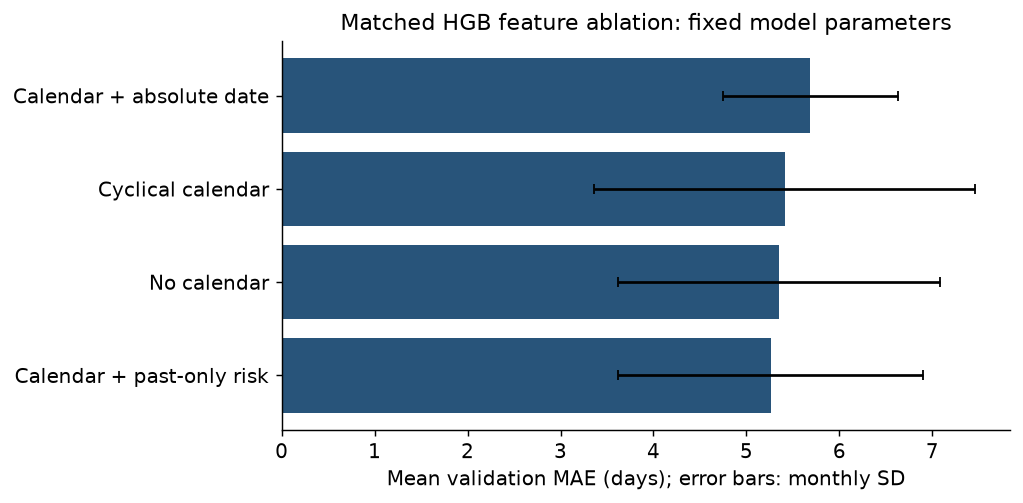

In [6]:
display(table("diagnostic_summary")[["candidate", "train_mae", "cv_mae", "cv_sd", "cv_rmse"]])
draw("06_calendar_ablation"); plt.show()

## 5. Ensemble Comparison

One convex Ridge/RF/HGB stack is compared. Every outer combiner is fitted using inner chronological predictions from its training partition. Base hyperparameters were previously selected using the main CV, so this is not a fully nested hyperparameter-selection estimate. The minimum retained gain is 1% versus the best single model.

,Measure,Value
0,Stack CV MAE,5.2971
1,Best single CV MAE,5.2595
2,Relative gain,-0.0071
3,Retained,False


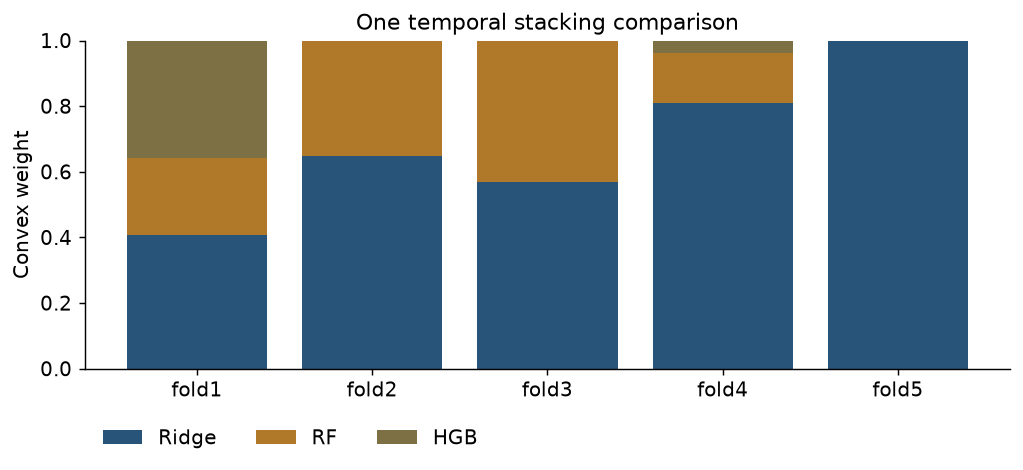

In [7]:
stack = read("stacking_complete.json")
display(pd.DataFrame({"Measure": ["Stack CV MAE", "Best single CV MAE", "Relative gain", "Retained"],
                      "Value": [stack["cv_mae"], stack["best_single_cv_mae"], stack["relative_gain"], stack["retained"]]}))
draw("08_stack_weights"); plt.show()

## 6. Frozen Train–Validation–Test Results

The test comparison list and selection hash were fixed before assessment. Training scores are in-sample; CV is an unweighted monthly mean with sample SD. The test is one later window. A discarded stack has no fabricated final Train/Test score.

,candidate,train_mae,cv_mae,cv_sd,test_mae
0,Convex_stack,—,5.2971,1.2865,—
1,HGB_leaves15_l21,4.7921,5.4140,2.0494,3.3969
2,HGB_risk,4.7190,5.2595,1.6386,3.4343
3,Mean,6.7601,7.1924,0.9719,6.6006
4,Median,6.4825,6.8824,1.6711,5.0603
5,OLS,5.2297,5.2900,1.2186,3.9111
6,Promise,12.6190,11.9915,1.5318,12.7181
7,RF_d12_l80,5.0905,5.4044,1.4978,4.1841
8,Ridge_a100,5.2397,5.2702,1.2454,3.8623
9,Tree_d6_l30,5.3562,5.5319,1.4980,4.2815


mae_reduction_vs_median   0.3213
minimum_reduction         0.0500
median_criterion_met        True
promise_criterion_met       True
dtype: object

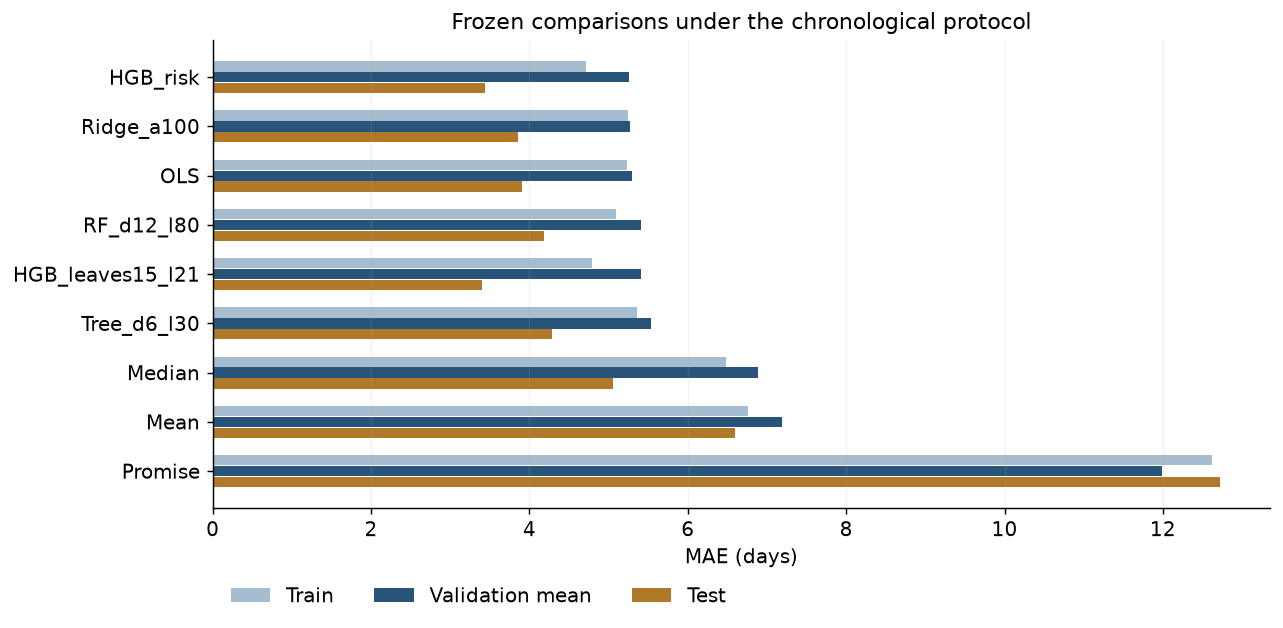

In [8]:
display(table("train_cv_test_comparison")[["candidate", "train_mae", "cv_mae", "cv_sd", "test_mae"]].fillna("—"))
display(pd.Series(read("test_summary.json")["success"]))
draw("02_model_comparison"); plt.show()

## 7. Monthly, Route and Long-Tail Error

An average error does not imply every order is within that range. Duration groups form a disjoint partition, enabling an error-contribution calculation. Route and chronology slices overlap and must not be added together.

,month,n,mae,rmse,r2,bias,within3
0,2018-06,6096,3.7000,5.6434,0.2706,1.4424,0.5139
1,2018-07,6156,3.6208,5.4062,0.2399,0.7352,0.5494
2,2018-08,6351,2.9984,4.1309,0.0927,0.8476,0.6125


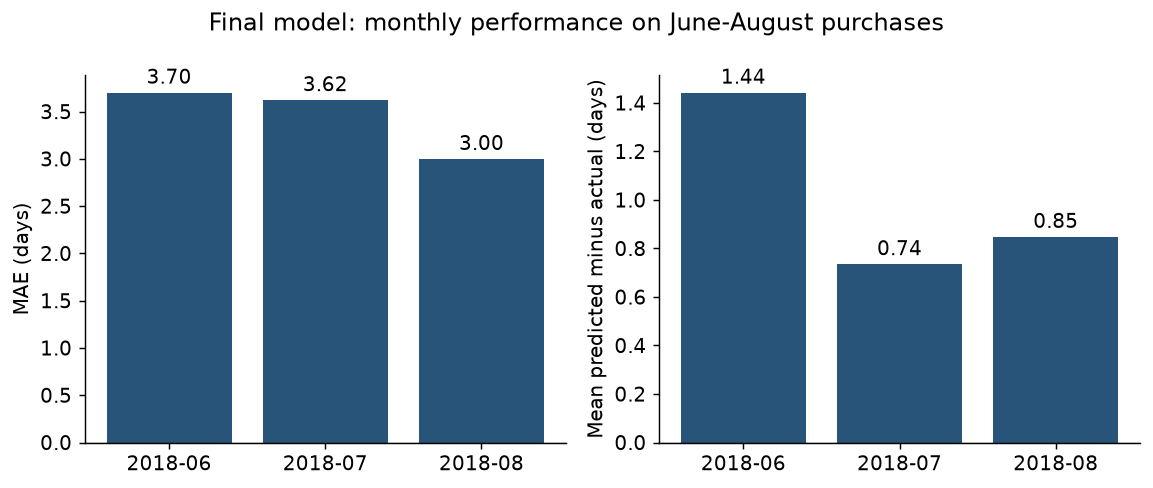

In [9]:
display(table("test_by_month"))
draw("03_test_months"); plt.show()

,group,n,mae,bias,order_share,absolute_error_share
0,0-14 days,16320,2.9613,1.9386,0.8773,0.7565
1,14-30 days,2112,5.2682,-4.0264,0.1135,0.1742
2,30-60 days,157,22.9545,-22.9545,0.0084,0.0564
3,>60 days,14,59.1375,-59.1375,0.0008,0.0130
4,Same-state,7491,2.3381,-0.3628,0.4027,0.2741
5,Cross-state,11112,4.1732,1.9276,0.5973,0.7259
6,Chronology flags removed,18569,3.4376,1.0049,0.9982,0.9991
7,Missing distance,79,5.0772,-1.0909,0.0042,0.0063


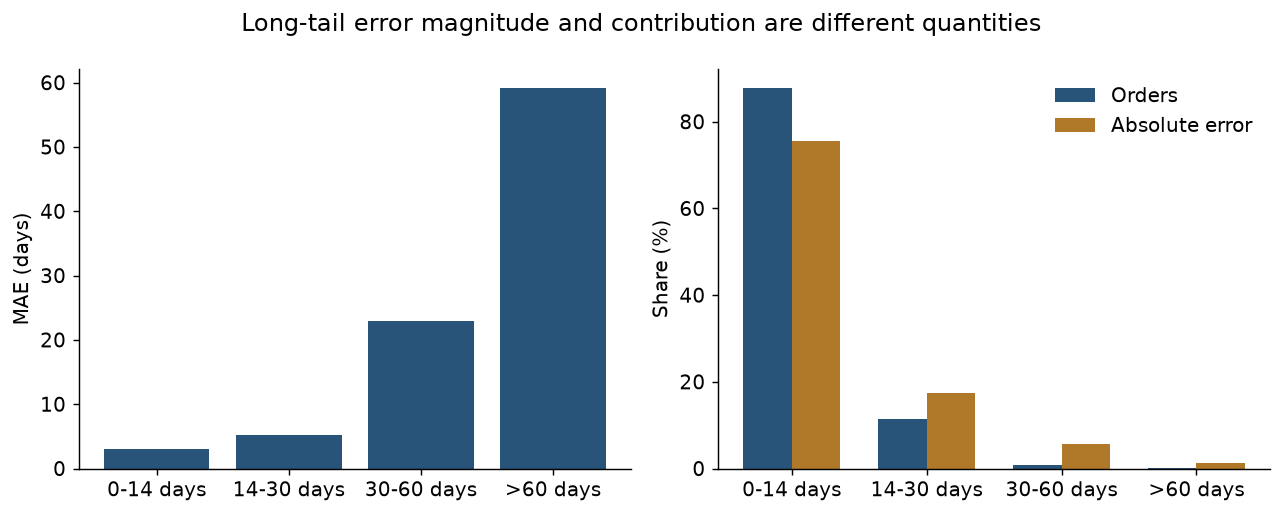

,primary_state_route,n,mae,absolute_error,absolute_error_share
0,SP|SP,6601,2.2877,"15,101.0211",0.2364
1,SP|RJ,1295,4.5121,"5,843.1155",0.0915
2,SP|MG,1247,3.4062,"4,247.4887",0.0665
3,SP|RS,585,4.2144,"2,465.4046",0.0386
4,PR|SP,581,3.2039,"1,861.4471",0.0291
5,SP|PR,569,2.9835,"1,697.5871",0.0266
6,MG|SP,427,3.3584,"1,434.0214",0.0224
7,SP|BA,426,6.5738,"2,800.4544",0.0438
8,SP|SC,361,3.6549,"1,319.4220",0.0207
9,MG|MG,322,2.3777,765.6125,0.0120


In [10]:
display(table("test_error_groups")[["group", "n", "mae", "bias", "order_share", "absolute_error_share"]])
draw("04_tail_errors"); plt.show()
display(table("test_by_route").head(10))

## 8. Validation-Based Feature Reliance

Groups of related input columns are shuffled jointly on May outcomes observed before final selection. Risk is recomputed from perturbed source inputs when applicable. The change in MAE measures predictive reliance, not a causal effect. Repeat SD describes permutation variability.

,group,mean,std
0,geography,1.0290,0.0404
1,promise,0.1527,0.0151
2,calendar,0.0512,0.0021
3,seller,0.0021,0.0032
4,product,-0.0003,0.0096
5,order,-0.0453,0.0167


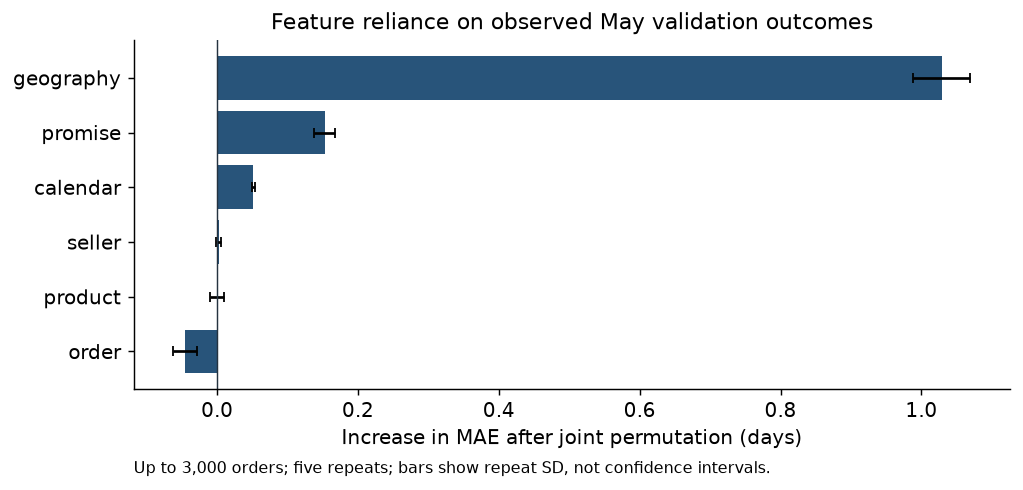

In [11]:
display(table("permutation_importance_groups"))
draw("05_importance"); plt.show()

## 9. Random Reference and Outcome-Maturity Diagnostic

The random reference uses the chronological single-model specification without tuning it again. Training eligibility, data mix and test populations differ, so its score difference is not isolated algorithm improvement. Eventual validation outcomes are examined only after freezing, without feeding model selection.

,Procedure,n,mae,rmse,r2
0,Chronological main,18603,3.4343,5.0925,0.2347
1,Random reference,31747,4.5868,8.1797,0.2968


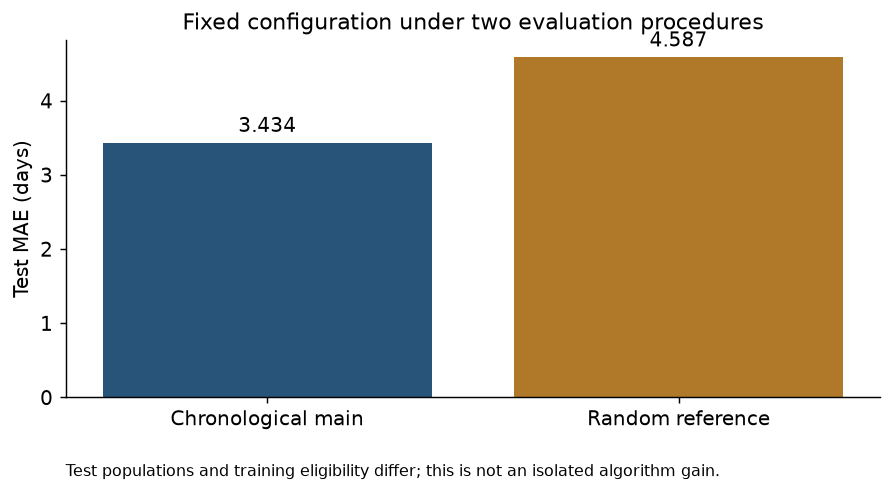

,fold,scope,n,mae,rmse
0,fold1,Selection-time observed,7068,5.5071,9.2912
1,fold1,Eventual completed outcomes,7069,5.5320,9.5393
2,fold2,Selection-time observed,6551,6.5494,10.6811
3,fold2,Eventual completed outcomes,6555,6.6362,11.3167
4,fold3,Selection-time observed,6996,6.8481,10.6071
5,fold3,Eventual completed outcomes,7003,6.9123,10.8455
6,fold4,Selection-time observed,6715,4.5929,5.9245
7,fold4,Eventual completed outcomes,6798,4.9354,7.1363
8,fold5,Selection-time observed,4406,2.8003,3.6337
9,fold5,Eventual completed outcomes,6749,4.4222,6.7485


In [12]:
comparison = table("chronological_vs_random")[["n", "mae", "rmse", "r2"]].copy()
comparison.insert(0, "Procedure", ["Chronological main", "Random reference"])
display(comparison)
draw("07_random_reference"); plt.show()
display(table("validation_outcome_maturity_diagnostic")[["fold", "scope", "n", "mae", "rmse"]])

## 10. Deployment and Reproducibility

`regression.score.predict_lead_time` returns predicted days, quoted days, a point-estimate comparison flag and an estimated arrival timestamp. The app must use the frozen bundle and held-out historical inputs. See `docs/regression/deployment_handoff.md` for exact inputs, errors and golden predictions.

A fresh run, from `Phase_3`, uses:
```bash
OLIST_ARCHIVE=/path/to/IT5006_Project-Data.zip python src/regression/run_pipeline.py --stage all --output-root /path/to/new_run
```
The reading notebook itself does not retrain models or alter the selected results.

## Conclusions and Limitations

The retained model meets both pre-set historical criteria: test MAE is 3.4343 days, 32.1% below the training-median reference, and lower than the quoted-promise error. Individual slow-order errors remain large. The risk-HGB advantage over Ridge in selection is small and sensitive to May coverage, so it does not establish stable superiority.

May’s incomplete selection labels, the conditional completed-delivery cohort, a short temporal record and prior exposure prevent treating this as untouched prospective confirmation. Deployment supports a demonstration; business benefit requires a separate pilot.

**AI declaration:** Codex assisted with code, checks, visualisation and writing. Numerical results are computed from the saved run; the team remains responsible for interpretation and submission.